# Методы обработки и распознавания изображений¶

## Практическое занятие 6: Построение простой CNN для классификации

### Пример 1: Классификация изображений cifar-10

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)
print(keras.__version__)

2.21.0
3.15.0


### 1. Создание простой CNN для CIFAR-10

In [2]:
model = keras.Sequential([
    # Первый блок: свертка + pooling
    layers.Conv2D(32, (3, 3), activation='relu', padding='same',
                  input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2), strides=2),

    # Второй блок: свертка + pooling
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=2),

    # Третий блок: свертка + pooling
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=2),

    # Полносвязные слои
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.summary()

C:\Users\SNTkachenko\AppData\Local\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 620,362 (2.37 MB)

 Trainable params: 620,362 (2.37 MB)

 Non-trainable params: 0 (0.00 B)

Число 620,362 это много или мало: основной вклад даёт слой Dense(256) после Flatten, потому что он связывает 2048 входов с 256 нейронами, а это уже более полумиллиона параметров.
Именно поэтому модель небольшая по глубине, но заметная по числу обучаемых весов.

Ожидаемая динамика размеров:
32x32x3
-> 32x32x32
-> 16x16x32
-> 16x16x64
-> 8x8x64
-> 8x8x128
-> 4x4x128
-> 2048
-> 256
-> 10

Анализ архитектуры:

•	Conv2D(32, 3×3) с padding='same': сохраняет размер 32×32

•	MaxPooling(2×2) со stride=2: уменьшает до 16×16
(уменьшение в 2 раза по каждой размерности → в 4 раза по объему)

•	Conv2D(64, 3×3) с padding='same': сохраняет размер 16×16

•	MaxPooling(2×2) со stride=2: уменьшает до 8×8

•	Conv2D(128, 3×3) с padding='same': сохраняет размер 8×8

•	MaxPooling(2×2) со stride=2: уменьшает до 4×4
Итоговый размер перед Flatten: 4×4×128 = 2048 нейронов

### 2. Детектор признаков с различными параметрами

In [3]:
import matplotlib.pyplot as plt
from scipy import signal

In [4]:
# Создадим небольшое синтетическое изображение
image = np.random.rand(64, 64) * 255
# Добавим некоторые признаки вручную
# Горизонтальная линия
image[20:25, 10:50] += 100
# Вертикальная линия
image[10:50, 35:40] += 100
# Диагональная линия
for i in range(30):
    image[i+10, i+10] += 50

In [5]:
# Определяем фильтры для разных признаков
vertical_edge = np.array([
[-1, 0, 1],
[-2, 0, 2],
[-1, 0, 1]
])
horizontal_edge = np.array([
[-1, -2, -1],
[0, 0, 0],
[1, 2, 1]
])
diagonal_edge = np.array([
[-1, -1, 0],
[-1, 0, 1],
[0, 1, 1]
])

In [6]:
# Применяем фильтры
def apply_filter(image, kernel):
    return np.abs(signal.convolve2d(image, kernel, mode='same'))
vertical_result = apply_filter(image, vertical_edge)
horizontal_result = apply_filter(image, horizontal_edge)
diagonal_result = apply_filter(image, diagonal_edge)

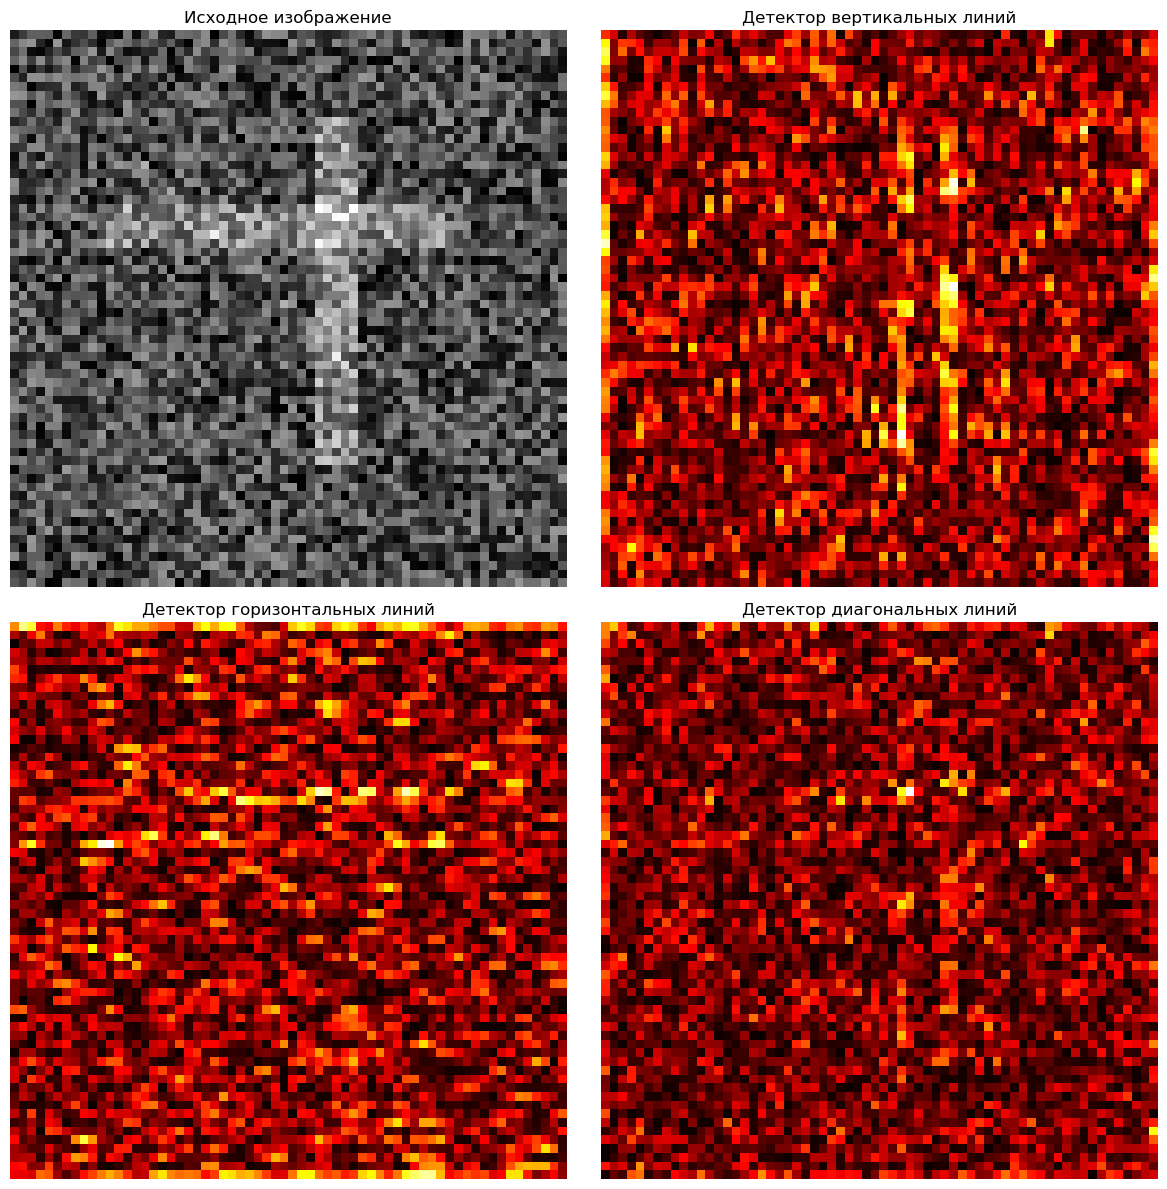

Вертикальные края: макс = 997.53, средний = 225.25
Горизонтальные края: макс = 986.78, средний = 222.45
Диагональные края: макс = 881.83, средний = 157.48


In [7]:
# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title('Исходное изображение')
axes[0, 0].axis('off')
axes[0, 1].imshow(vertical_result, cmap='hot')
axes[0, 1].set_title('Детектор вертикальных линий')
axes[0, 1].axis('off')
axes[1, 0].imshow(horizontal_result, cmap='hot')
axes[1, 0].set_title('Детектор горизонтальных линий')
axes[1, 0].axis('off')
axes[1, 1].imshow(diagonal_result, cmap='hot')
axes[1, 1].set_title('Детектор диагональных линий')
axes[1, 1].axis('off')
plt.tight_layout()
plt.show()
print(f"Вертикальные края: макс = {np.max(vertical_result):.2f}, средний = {np.mean(vertical_result):.2f}")
print(f"Горизонтальные края: макс = {np.max(horizontal_result):.2f}, средний = {np.mean(horizontal_result):.2f}")
print(f"Диагональные края: макс = {np.max(diagonal_result):.2f}, средний = {np.mean(diagonal_result):.2f}")

Пример не очень выразительный, но тем не менее...

Возмем почти чёрный фон и нарисуем на нём несколько контрастных геометрических примитивов: одну вертикальную, одну горизонтальную и одну диагональную линию.

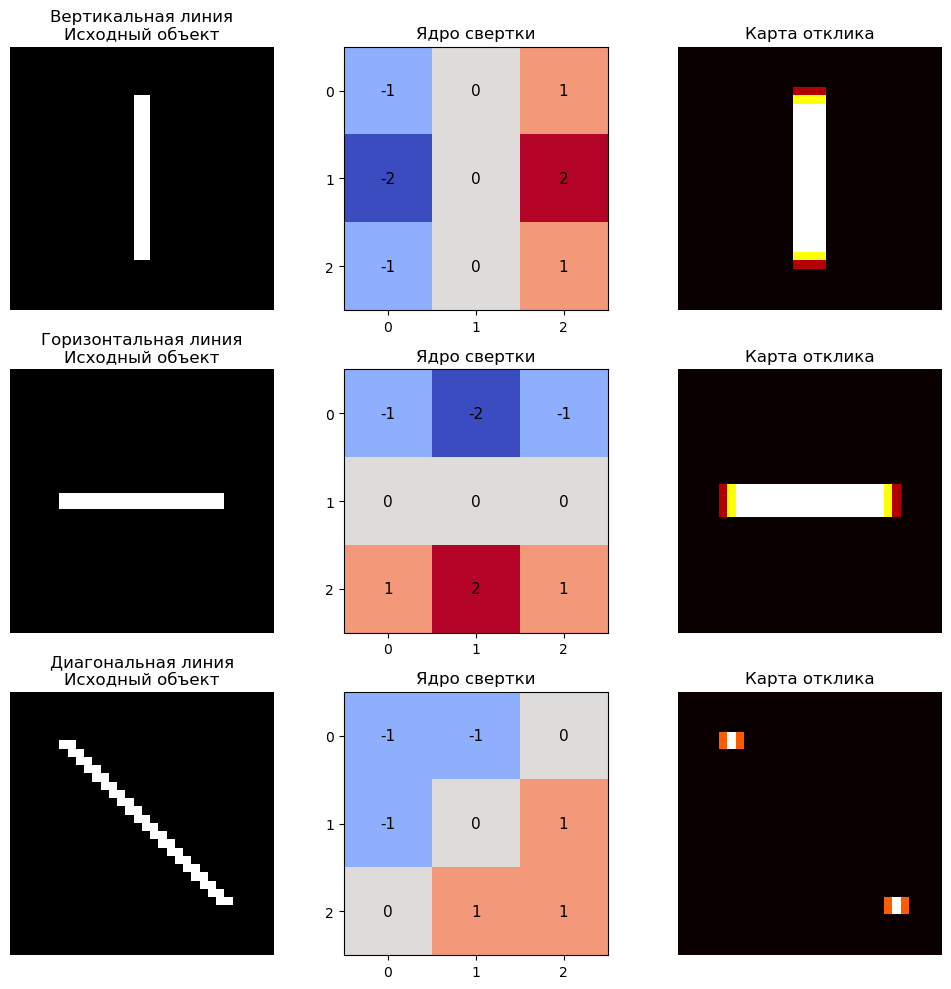

In [8]:
# -------------------------------------------------
# Функции для генерации простых синтетических изображений
# -------------------------------------------------
def create_vertical_line_image(size=32):
    image = np.zeros((size, size), dtype=np.float32)
    image[6:size-6, size//2-1:size//2+1] = 255
    return image

def create_horizontal_line_image(size=32):
    image = np.zeros((size, size), dtype=np.float32)
    image[size//2-1:size//2+1, 6:size-6] = 255
    return image

def create_diagonal_line_image(size=32):
    image = np.zeros((size, size), dtype=np.float32)
    for i in range(6, size-6):
        image[i, i] = 255
        if i + 1 < size:
            image[i, i + 1] = 255
    return image

# -------------------------------------------------
# Ядра свертки
# -------------------------------------------------
vertical_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

horizontal_kernel = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

diagonal_kernel = np.array([
    [-1, -1, 0],
    [-1,  0, 1],
    [ 0,  1, 1]
], dtype=np.float32)

# -------------------------------------------------
# Функция применения фильтра
# -------------------------------------------------
def apply_filter(image, kernel):
    return np.abs(signal.convolve2d(image, kernel, mode='same'))

# -------------------------------------------------
# Формируем три тестовых изображения
# -------------------------------------------------
vertical_image = create_vertical_line_image()
horizontal_image = create_horizontal_line_image()
diagonal_image = create_diagonal_line_image()

# -------------------------------------------------
# Вычисляем отклики "правильных" фильтров
# -------------------------------------------------
vertical_response = apply_filter(vertical_image, vertical_kernel)
horizontal_response = apply_filter(horizontal_image, horizontal_kernel)
diagonal_response = apply_filter(diagonal_image, diagonal_kernel)

# -------------------------------------------------
# Подготовка данных для единой визуализации
# -------------------------------------------------
examples = [
    ("Вертикальная линия", vertical_image, vertical_kernel, vertical_response),
    ("Горизонтальная линия", horizontal_image, horizontal_kernel, horizontal_response),
    ("Диагональная линия", diagonal_image, diagonal_kernel, diagonal_response),
]

# -------------------------------------------------
# Визуализация: объект → ядро → карта отклика
# -------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row, (title, image, kernel, response) in enumerate(examples):
    # Исходный объект
    axes[row, 0].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'{title}\nИсходный объект')
    axes[row, 0].axis('off')

    # Ядро свертки
    im_kernel = axes[row, 1].imshow(kernel, cmap='coolwarm', vmin=-2, vmax=2)
    axes[row, 1].set_title('Ядро свертки')
    axes[row, 1].set_xticks([0, 1, 2])
    axes[row, 1].set_yticks([0, 1, 2])

    for i in range(3):
        for j in range(3):
            axes[row, 1].text(j, i, f'{kernel[i, j]:.0f}',
                              ha='center', va='center', color='black', fontsize=11)

    # Карта отклика
    axes[row, 2].imshow(response, cmap='hot')
    axes[row, 2].set_title('Карта отклика')
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()

Вертикальное ядро даёт максимальный отклик на вертикальной структуре, горизонтальное — на горизонтальной, диагональное — на наклонной. Это и есть базовая идея ранних сверточных слоёв CNN, которые учатся выделять ориентированные границы и простые локальные признаки.

Сделаем одну фигуру 3×4: в строках будут три объекта — вертикальная, горизонтальная и диагональная линия; в первом столбце будет сам объект, а в следующих трёх — отклики после вертикального, горизонтального и диагонального фильтра. Такая структура наглядно показывает перекрёстные отклики и позволяет сравнить "силу" ответа разных ядер на один и тот же вход.

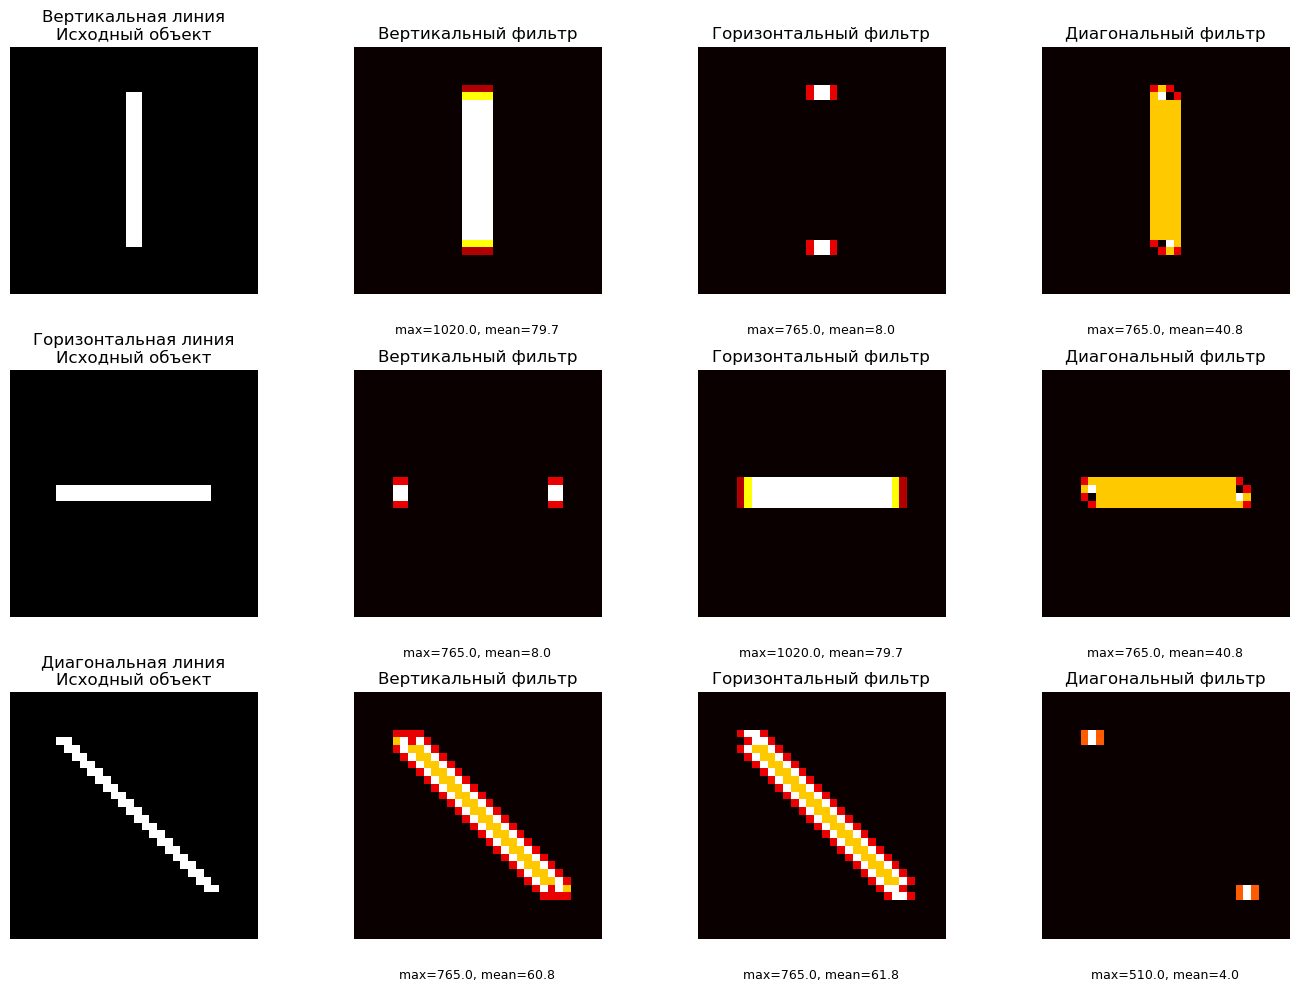

In [9]:
# -------------------------------------------------
# Функции генерации простых синтетических изображений
# -------------------------------------------------
def create_vertical_line_image(size=32):
    image = np.zeros((size, size), dtype=np.float32)
    image[6:size-6, size//2-1:size//2+1] = 255
    return image

def create_horizontal_line_image(size=32):
    image = np.zeros((size, size), dtype=np.float32)
    image[size//2-1:size//2+1, 6:size-6] = 255
    return image

def create_diagonal_line_image(size=32):
    image = np.zeros((size, size), dtype=np.float32)
    for i in range(6, size-6):
        image[i, i] = 255
        if i + 1 < size:
            image[i, i + 1] = 255
    return image

# -------------------------------------------------
# Ядра свертки
# -------------------------------------------------
vertical_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

horizontal_kernel = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

diagonal_kernel = np.array([
    [-1, -1, 0],
    [-1,  0, 1],
    [ 0,  1, 1]
], dtype=np.float32)

kernels = [
    ("Вертикальный фильтр", vertical_kernel),
    ("Горизонтальный фильтр", horizontal_kernel),
    ("Диагональный фильтр", diagonal_kernel),
]

# -------------------------------------------------
# Функция применения фильтра
# -------------------------------------------------
def apply_filter(image, kernel):
    return np.abs(signal.convolve2d(image, kernel, mode='same'))

# -------------------------------------------------
# Формируем тестовые изображения
# -------------------------------------------------
images = [
    ("Вертикальная линия", create_vertical_line_image()),
    ("Горизонтальная линия", create_horizontal_line_image()),
    ("Диагональная линия", create_diagonal_line_image()),
]

# -------------------------------------------------
# Визуализация перекрестных откликов
# -------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, (image_name, image) in enumerate(images):
    # Первый столбец — исходный объект
    axes[row, 0].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'{image_name}\nИсходный объект')
    axes[row, 0].axis('off')

    # Остальные столбцы — отклики всех фильтров
    for col, (kernel_name, kernel) in enumerate(kernels, start=1):
        response = apply_filter(image, kernel)

        axes[row, col].imshow(response, cmap='hot')
        axes[row, col].set_title(kernel_name)
        axes[row, col].axis('off')

        max_response = np.max(response)
        mean_response = np.mean(response)

        axes[row, col].text(
            0.5, -0.12,
            f'max={max_response:.1f}, mean={mean_response:.1f}',
            transform=axes[row, col].transAxes,
            ha='center', va='top', fontsize=9
        )

plt.tight_layout()
plt.show()

У “правильной” пары объект–фильтр карта отклика обычно будет ярче и структурно чище, чем у “неправильных” сочетаний. Это хорошо демонстрирует, что ядро свёртки ведёт себя как детектор определённой локальной геометрии, а не как универсальный усилитель всех контуров сразу.

### 3. Эффект параметров на выходной размер

In [12]:
# Влияние параметров свертки на размер выходного изображения
def analyze_conv_output(input_h, input_w, kernel_size, padding, stride):
    output_h = (input_h - kernel_size + 2 * padding) // stride + 1
    output_w = (input_w - kernel_size + 2 * padding) // stride + 1
    reduction = (input_h * input_w) / (output_h * output_w)
    return output_h, output_w, reduction

print("=" * 70)
print("Таблица влияния параметров на размер выхода")
print("=" * 70)
print("Входное изображение: 224×224 (типичный размер для ImageNet)")
print()

# Задаем несколько характерных конфигураций сверточного слоя
configs = [
    (3, 1, 1),  # Ядро 3x3, padding=1, stride=1
    (5, 2, 1),  # Ядро 5x5, padding=2, stride=1
    (3, 0, 1),  # Ядро 3x3, padding=0, stride=1
    (3, 1, 2),  # Ядро 3x3, padding=1, stride=2
    (5, 2, 2),  # Ядро 5x5, padding=2, stride=2
]

print(f"{'Конфигурация':<20} {'Выходной размер':<20} {'Уменьшение площади':<20}")
print("-" * 70)

for kernel, padding, stride in configs:
    out_h, out_w, reduction = analyze_conv_output(224, 224, kernel, padding, stride)
    config_str = f"K={kernel}, P={padding}, S={stride}"
    output_str = f"{out_h}×{out_w}"
    print(f"{config_str:<20} {output_str:<20} {reduction:.2f}x")

print("\nВыводы:")
print("- Padding типа same сохраняет размер изображения при stride=1.")
print("- Увеличение stride уменьшает пространственное разрешение выхода.")
print("- При padding=0 размер выхода уменьшается даже при stride=1.")

Таблица влияния параметров на размер выхода
Входное изображение: 224×224 (типичный размер для ImageNet)

Конфигурация         Выходной размер      Уменьшение площади  
----------------------------------------------------------------------
K=3, P=1, S=1        224×224              1.00x
K=5, P=2, S=1        224×224              1.00x
K=3, P=0, S=1        222×222              1.02x
K=3, P=1, S=2        112×112              4.00x
K=5, P=2, S=2        112×112              4.00x

Выводы:
- Padding типа same сохраняет размер изображения при stride=1.
- Увеличение stride уменьшает пространственное разрешение выхода.
- При padding=0 размер выхода уменьшается даже при stride=1.


В данном примере исследуется влияние основных параметров свёрточного слоя — размера ядра, дополнения нулями (padding) и шага перемещения фильтра (stride) — на пространственный размер выходного изображения. Понимание этой зависимости особенно важно при проектировании архитектуры CNN, поскольку последовательное применение свёрток и пулинга изменяет разрешение признаковых карт и, следовательно, вычислительную сложность всей сети.

Для наглядности рассмотрим несколько типичных конфигураций свёрточного слоя и вычислим размер выходного тензора для изображения размером 224×224. Такой размер часто используется в задачах компьютерного зрения и является стандартным, например, для моделей, обучаемых на ImageNet.

Результаты вычислений показывают, что при stride = 1 и выборе padding, компенсирующего размер ядра, пространственные размеры выхода сохраняются. Именно поэтому конфигурации вида 3×3, padding=1, stride=1 и 5×5, padding=2, stride=1 широко применяются в свёрточных сетях: они позволяют извлекать признаки, не уменьшая размер карты активаций на каждом шаге.

Если padding = 0, то выходное изображение становится меньше уже после одной операции свёртки. Это связано с тем, что фильтр не может быть центрирован у границ изображения без выхода за его пределы, поэтому часть пикселей по краям теряется.

Особенно заметное влияние оказывает параметр stride. При увеличении шага до 2 размер выхода уменьшается примерно вдвое по каждой координате, что означает сокращение площади карты признаков примерно в четыре раза. Такой механизм позволяет быстро уменьшать размерность данных и снижать вычислительные затраты, однако слишком агрессивное уменьшение может привести к потере важных локальных деталей.

С практической точки зрения данный пример показывает, что параметры свёрточного слоя определяют не только характер извлекаемых признаков, но и всю дальнейшую геометрию вычислений в сети. При проектировании CNN необходимо контролировать, на каких этапах сеть сохраняет пространственное разрешение, а на каких — уменьшает его ради повышения вычислительной эффективности.

Именно поэтому в современных архитектурах глубокого обучения выбор значений kernel_size, padding и stride рассматривается как важный элемент проектирования модели, влияющий как на точность, так и на стоимость вычислений.

### 4. Построение полной CNN с анализом размеров

In [15]:
# Выводим изменение размеров тензора при прохождении через сверточную сеть
def print_network_flow(input_shape, title):
    layers_config = [
        ("Input",   None, None, None, None),
        ("Conv2D",  32,   3,    1,    1),
        ("ReLU",    None, None, None, None),
        ("MaxPool", None, 2,    0,    2),
        ("Conv2D",  64,   3,    1,    1),
        ("ReLU",    None, None, None, None),
        ("MaxPool", None, 2,    0,    2),
        ("Conv2D",  128,  3,    1,    1),
        ("ReLU",    None, None, None, None),
        ("Flatten", None, None, None, None),
        ("Dense",   256,  None, None, None),
        ("ReLU",    None, None, None, None),
        ("Dense",   10,   None, None, None),
    ]

    current_shape = input_shape
    total_params = 0

    print(f"\n{title}")
    print("-" * 80)
    print(f"{'Слой':<15} {'Параметры слоя':<30} {'Выходная форма':<20} {'Число параметров'}")
    print("-" * 80)

    for layer_name, units, kernel, padding, stride in layers_config:
        if layer_name == "Input":
            print(f"{layer_name:<15} {'-':<30} {str(current_shape):<20} 0")

        elif layer_name == "Conv2D":
            h, w, c = current_shape
            k = kernel
            p = padding
            s = stride

            new_h = (h - k + 2 * p) // s + 1
            new_w = (w - k + 2 * p) // s + 1
            new_c = units

            params = k * k * c * units + units
            total_params += params

            current_shape = (new_h, new_w, new_c)
            layer_info = f"{c}->{units}, K={k}, P={p}, S={s}"
            print(f"{layer_name:<15} {layer_info:<30} {str(current_shape):<20} {params}")

        elif layer_name == "MaxPool":
            h, w, c = current_shape
            k = kernel
            s = stride

            new_h = (h - k) // s + 1
            new_w = (w - k) // s + 1

            current_shape = (new_h, new_w, c)
            layer_info = f"K={k}, S={s}"
            print(f"{layer_name:<15} {layer_info:<30} {str(current_shape):<20} 0")

        elif layer_name == "Flatten":
            flat_size = np.prod(current_shape)
            current_shape = (flat_size,)
            print(f"{layer_name:<15} {'-':<30} {str(current_shape):<20} 0")

        elif layer_name == "Dense":
            input_units = current_shape[0]
            params = input_units * units + units
            total_params += params

            current_shape = (units,)
            layer_info = f"{input_units}->{units}"
            print(f"{layer_name:<15} {layer_info:<30} {str(current_shape):<20} {params}")

        elif layer_name == "ReLU":
            print(f"{layer_name:<15} {'активация':<30} {str(current_shape):<20} 0")

    print("-" * 80)
    print(f"{'Итого':<67} {total_params}")

print("Архитектура CNN и прохождение размеров через сеть")
print("=" * 80)

print_network_flow((32, 32, 3), "Вариант 1: входное изображение 32×32×3")
print_network_flow((224, 224, 3), "Вариант 2: входное изображение 224×224×3")

Архитектура CNN и прохождение размеров через сеть

Вариант 1: входное изображение 32×32×3
--------------------------------------------------------------------------------
Слой            Параметры слоя                 Выходная форма       Число параметров
--------------------------------------------------------------------------------
Input           -                              (32, 32, 3)          0
Conv2D          3->32, K=3, P=1, S=1           (32, 32, 32)         896
ReLU            активация                      (32, 32, 32)         0
MaxPool         K=2, S=2                       (16, 16, 32)         0
Conv2D          32->64, K=3, P=1, S=1          (16, 16, 64)         18496
ReLU            активация                      (16, 16, 64)         0
MaxPool         K=2, S=2                       (8, 8, 64)           0
Conv2D          64->128, K=3, P=1, S=1         (8, 8, 128)          73856
ReLU            активация                      (8, 8, 128)          0
Flatten         -      

### Задание:

Изменяя параметры получите различные сочетания параметров нейронной сети.